In [7]:
from pathlib import Path
import pandas as pd

current_dir = Path.cwd()

for folder in [current_dir, *current_dir.parents]:
    train_path = folder / "data" / "raw" / "train.csv"
    if train_path.is_file():
        break
train = pd.read_csv(train_path)

for folder in [current_dir, *current_dir.parents]:
    train_demographics_path = folder / "data" / "raw" / "train_demographics.csv"
    if train_demographics_path.is_file():
        break
train_demographics = pd.read_csv(train_demographics_path)

print("Kích thước:", train.shape)
print("Số chuỗi:", train["sequence_id"].nunique())
print("Số người:", train["subject"].nunique())

display(train.head())
train.info()

Kích thước: (574945, 341)
Số chuỗi: 8151
Số người: 81


,row_id,sequence_type,sequence_id,sequence_counter,subject,orientation,behavior,phase,gesture,acc_x,...,tof_5_v54,tof_5_v55,tof_5_v56,tof_5_v57,tof_5_v58,tof_5_v59,tof_5_v60,tof_5_v61,tof_5_v62,tof_5_v63
0,SEQ_000007_000000,Target,SEQ_000007,0,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.683594,...,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1,SEQ_000007_000001,Target,SEQ_000007,1,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.949219,...,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
2,SEQ_000007_000002,Target,SEQ_000007,2,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,5.722656,...,-1.0,-1.0,112.0,119.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
3,SEQ_000007_000003,Target,SEQ_000007,3,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.601562,...,-1.0,-1.0,101.0,111.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
4,SEQ_000007_000004,Target,SEQ_000007,4,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,5.566406,...,-1.0,-1.0,101.0,109.0,125.0,-1.0,-1.0,-1.0,-1.0,-1.0


<class 'pandas.DataFrame'>
RangeIndex: 574945 entries, 0 to 574944
Columns: 341 entries, row_id to tof_5_v63
dtypes: float64(332), int64(1), str(8)
memory usage: 1.5 GB


In [9]:
# Kiểm tra mỗi chuỗi có đúng một người và một nhãn
check = train.groupby("sequence_id")[["subject", "gesture"]].nunique()
print(check.max())

# Tạo bảng: mỗi hàng đại diện cho một chuỗi
sequences = (
    train.groupby("sequence_id", sort=False)
    .agg(
        subject=("subject", "first"),
        gesture=("gesture", "first"),
        length=("sequence_counter", "size")
    )
)

display(sequences.head())
display(sequences["gesture"].value_counts())
display(sequences["length"].describe())
display(sequences.groupby("subject").size().describe())

subject    1
gesture    1
dtype: int64


,subject,gesture,length
sequence_id,,,
SEQ_000007,SUBJ_059520,Cheek - pinch skin,57
SEQ_000008,SUBJ_020948,Forehead - pull hairline,68
SEQ_000013,SUBJ_040282,Cheek - pinch skin,53
SEQ_000016,SUBJ_052342,Write name on leg,61
SEQ_000018,SUBJ_032165,Forehead - pull hairline,54


gesture
Forehead - pull hairline                      640
Neck - scratch                                640
Neck - pinch skin                             640
Eyelash - pull hair                           640
Forehead - scratch                            640
Text on phone                                 640
Eyebrow - pull hair                           638
Above ear - pull hair                         638
Cheek - pinch skin                            637
Wave hello                                    478
Write name in air                             477
Pull air toward your face                     477
Write name on leg                             161
Feel around in tray and pull out an object    161
Pinch knee/leg skin                           161
Scratch knee/leg skin                         161
Drink from bottle/cup                         161
Glasses on/off                                161
Name: count, dtype: int64

count    8151.000000
mean       70.536744
std        35.389879
min        29.000000
25%        51.000000
50%        59.000000
75%        78.000000
max       700.000000
Name: length, dtype: float64

count     81.000000
mean     100.629630
std        7.757971
min       51.000000
25%      102.000000
50%      102.000000
75%      102.000000
max      102.000000
dtype: float64

In [11]:
imu_cols = [
    "acc_x", "acc_y", "acc_z",
    "rot_w", "rot_x", "rot_y", "rot_z"
]

missing_rate = train[imu_cols].isna().sum().sort_values(ascending=False)
display(missing_rate)

rot_y    3692
rot_x    3692
rot_w    3692
rot_z    3692
acc_z       0
acc_x       0
acc_y       0
dtype: int64

In [16]:
missing_by_sequence = (
    train[imu_cols].isna()
    .groupby(train["sequence_id"])
    .mean()
)

display(missing_by_sequence.describe())

,acc_x,acc_y,acc_z,rot_w,rot_x,rot_y,rot_z
count,8151.0,8151.0,8151.0,8151.000000,8151.000000,8151.000000,8151.000000
mean,0.0,0.0,0.0,0.006134,0.006134,0.006134,0.006134
std,0.0,0.0,0.0,0.078085,0.078085,0.078085,0.078085
min,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
50%,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
75%,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
max,0.0,0.0,0.0,1.000000,1.000000,1.000000,1.000000


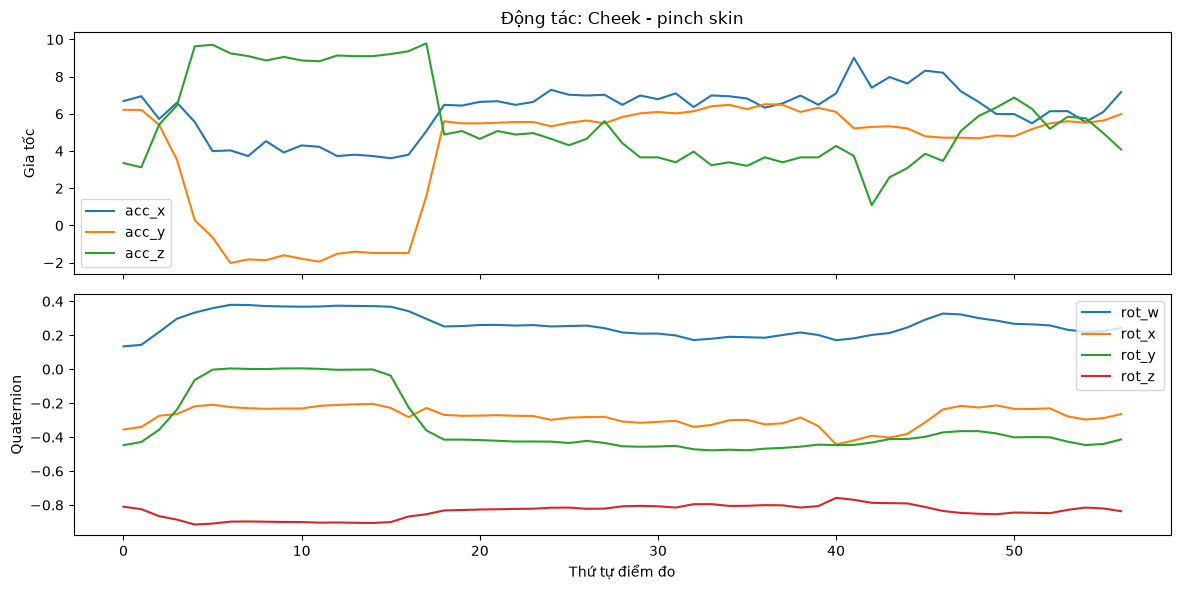

In [21]:
import matplotlib.pyplot as plt

sequence_id = sequences.index[0]

sample = (
    train.loc[train["sequence_id"] == sequence_id]
    .sort_values("sequence_counter")
)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

sample.plot(
    x="sequence_counter",
    y=["acc_x", "acc_y", "acc_z"],
    ax=axes[0]
)

sample.plot(
    x="sequence_counter",
    y=["rot_w", "rot_x", "rot_y", "rot_z"],
    ax=axes[1]
)

axes[0].set_title(f"Động tác: {sample['gesture'].iloc[0]}")
axes[0].set_ylabel("Gia tốc")
axes[1].set_ylabel("Quaternion")
axes[1].set_xlabel("Thứ tự điểm đo")

plt.tight_layout()
plt.show()